# Exploratory Data Analysis: Retail Customer Sales Data
**Data Analyst Training Program — Mini Project**

---

### 1. Introduction
A retail company has collected two years (2023–2024) of transaction-level sales and customer data across four regions of India. Before this data can be trusted for dashboards, statistical modeling, or business decisions, it must be systematically audited, cleaned, and profiled.

In this notebook, I perform a complete Exploratory Data Analysis (EDA) on `retail_customer_sales_dataset.csv`—auditing data quality, applying justified cleaning decisions, examining distributions and outliers, engineering new features, and answering key business questions.

---

### 2. Project Objectives
1. **Setup & First Look:** Load the dataset and inspect its shape, column names, data types, and sample rows.
2. **Data Quality Audit:** Identify missing values (counts and percentages), duplicate records, inconsistent category labels (`Gender` and `Region`), impossible numerical entries, and date format/timeline errors.
3. **Justified Data Cleaning:** Standardize text and dates, handle duplicates, and impute or flag missing/invalid values with clear explanations.
4. **Descriptive Statistics & Univariate Analysis:** Compute mean, median, mode, standard deviation, variance, quartiles, IQR, and skewness for key numerical variables, plus frequency and proportion breakdowns for categorical columns.
5. **Outlier Detection:** Apply the IQR method to `Sales`, `Profit`, `Age`, and `Income`, and evaluate whether flagged values are genuine extreme cases or errors.
6. **Feature Engineering & Business Insights:** Create calculated columns (`Profit_Margin`, `Delivery_Days`, `Order_Year`) and answer 5 business questions using `groupby()` aggregations.

### 3.1 Setup and First Look
Importing the required Python libraries (`pandas`, `numpy`, `matplotlib`, and `seaborn`) and loading `retail_customer_sales_dataset.csv`.

In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('retail_customer_sales_dataset.csv')

Checking the dataset shape, column names, data types, and the first and last few rows.

In [66]:
print("Shape (Rows, Columns):", df.shape)
print("\nColumn Data Types:\n", df.dtypes)
display(df.head())
display(df.tail())

Shape (Rows, Columns): (7084, 24)

Column Data Types:
 Transaction_ID            str
Customer_ID               str
Order_Date                str
Delivery_Date             str
Age                   float64
Gender                    str
Income                float64
Region                    str
State                     str
City                      str
Customer_Segment          str
Product_Category          str
Product                   str
Quantity                int64
Unit_Price            float64
Discount              float64
Sales                 float64
Cost                  float64
Profit                float64
Payment_Method            str
Delivery_Mode             str
Customer_Rating       float64
Satisfaction_Level        str
Returned                  str
dtype: object


,Transaction_ID,Customer_ID,Order_Date,Delivery_Date,Age,Gender,Income,Region,State,City,...,Unit_Price,Discount,Sales,Cost,Profit,Payment_Method,Delivery_Mode,Customer_Rating,Satisfaction_Level,Returned
0,TXN205933,CUST10816,2023-12-19,2023-12-25,38.0,Male,62828.52,West,Gujarat,Surat,...,887.94,0.32,1811.40,1204.47,606.93,Debit Card,Standard,3.0,Low,No
1,TXN201247,CUST10916,2023-09-30,2023-10-04,42.0,Male,50952.64,North,Haryana,Gurugram,...,14309.96,0.18,23468.33,17137.06,6331.27,Credit Card,Standard,3.0,High,No
2,TXN202714,CUST11352,2023-01-12,2023-01-20,41.0,Male,60476.00,East,Jharkhand,Ranchi,...,710.95,0.09,2587.86,1577.83,1010.03,Debit Card,Express,3.0,Medium,No
3,TXN206797,CUST11551,2024-06-06,2024-06-10,33.0,Male,41516.94,West,Gujarat,Surat,...,332.48,0.34,877.75,556.78,320.97,Debit Card,Standard,3.0,Medium,No
4,TXN203937,CUST10855,2024-09-23,2024-09-30,29.0,Female,95727.49,north,Haryana,Gurugram,...,10542.13,0.21,8328.28,5528.47,2799.81,UPI,Express,1.0,Low,No


,Transaction_ID,Customer_ID,Order_Date,Delivery_Date,Age,Gender,Income,Region,State,City,...,Unit_Price,Discount,Sales,Cost,Profit,Payment_Method,Delivery_Mode,Customer_Rating,Satisfaction_Level,Returned
7079,TXN201768,CUST10870,2024-10-22,2024-10-27,34.0,Male,79446.58,East,Odisha,Bhubaneswar,...,5395.38,0.09,4909.80,3273.47,1636.33,Net Banking,Express,2.0,Low,Yes
7080,TXN201737,CUST10314,2024-10-05,2024-10-14,50.0,Male,21796.92,East,West Bengal,Durgapur,...,1603.82,0.02,4715.23,2923.68,1791.55,Credit Card,Standard,4.0,High,No
7081,TXN203240,CUST10859,2024-06-04,2024-06-15,42.0,Male,60621.27,West,Gujarat,Surat,...,11519.59,0.22,8985.28,5360.01,3625.27,UPI,Standard,2.0,Medium,No
7082,TXN205305,CUST10829,2024-03-31,2024-04-08,32.0,Female,42178.47,South,Kerala,Kozhikode,...,980.67,0.21,2324.19,1812.17,512.02,UPI,Standard,4.0,High,No
7083,TXN204737,CUST10847,2024-10-18,2024-10-26,63.0,Male,44113.29,South,Kerala,Kozhikode,...,3727.59,0.30,5218.63,3932.52,1286.11,Debit Card,Standard,4.0,High,No


### 3.2 Data Quality Audit
Checking missing values per column (both raw count and percentage of total rows).

In [67]:
missing = df.isnull().sum()
missing_percent = (missing / len(df) * 100).round(2)

missing_report = pd.DataFrame({
    'Missing_Count': missing,
    'Missing_Pct (%)': missing_percent
})
print(missing_report[missing_report['Missing_Count'] > 0])

                    Missing_Count  Missing_Pct (%)
Delivery_Date                 106             1.50
Age                           142             2.00
Income                        253             3.57
Discount                       71             1.00
Customer_Rating               428             6.04
Satisfaction_Level            179             2.53


Checking exact duplicate rows and duplicate `Transaction_ID` entries.

In [68]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate Transaction IDs:", df['Transaction_ID'].duplicated().sum())

Exact duplicate rows: 61
Duplicate Transaction IDs: 84


Checking inconsistent category spellings and casing in `Gender`, `Region`, and other categorical columns.

In [69]:
print("Gender values:", df['Gender'].unique())
print("Region values:", df['Region'].unique())
print("Customer_Segment values:", df['Customer_Segment'].unique())
print("Product_Category values:", df['Product_Category'].unique())

Gender values: <StringArray>
['Male', 'Female', 'male', 'M', 'FEMALE', 'female', 'F', 'MALE']
Length: 8, dtype: str
Region values: <StringArray>
[ 'West', 'North',  'East', 'north', 'South',  'west', 'south',   'Sth',
  'east', 'NORTH',  'Nort',  'WEST']
Length: 12, dtype: str
Customer_Segment values: <StringArray>
['Consumer', 'Home Office', 'Corporate']
Length: 3, dtype: str
Product_Category values: <StringArray>
['Grocery', 'Electronics', 'Clothing', 'Furniture', 'Office Supplies']
Length: 5, dtype: str


Checking impossible or out-of-range values in `Age` (valid range 18–100) and `Discount` (valid range 0–0.5), as well as date format inconsistencies and cases where `Delivery_Date` is earlier than `Order_Date`.

In [70]:
# Out-of-range numerical values
invalid_age = df[(df['Age'] < 18) | (df['Age'] > 100)]
invalid_disc = df[(df['Discount'] < 0) | (df['Discount'] > 0.5)]

print("Invalid Ages (<18 or >100):", len(invalid_age))
print(invalid_age[['Transaction_ID', 'Age']])

print("\nInvalid Discounts (<0 or >0.5):", len(invalid_disc))
print(invalid_disc[['Transaction_ID', 'Discount']])

# Date format & timeline audit
print("\nSample Order_Date formats:", df['Order_Date'].iloc[25:35].tolist())
od_temp = pd.to_datetime(df['Order_Date'], format='mixed', errors='coerce')
dd_temp = pd.to_datetime(df['Delivery_Date'], format='mixed', errors='coerce')
print("Orders where Delivery_Date < Order_Date:", (dd_temp < od_temp).sum())

Invalid Ages (<18 or >100): 6
     Transaction_ID    Age
3106      TXN203870   -5.0
3202      TXN203970  180.0
3618      TXN203574  999.0
3982      TXN200566  -12.0
4879      TXN205808  150.0
5888      TXN201101   -1.0

Invalid Discounts (<0 or >0.5): 6
     Transaction_ID  Discount
1196      TXN203944      -0.2
2624      TXN206629       2.0
3165      TXN203047       1.1
4174      TXN200564       1.5
5410      TXN204333      -0.1
6693      TXN205595       1.2

Sample Order_Date formats: ['2024-06-07', '2024-10-18', '2024-03-13', '2024-01-10', '2024-03-29', '2023-08-31', '2024-08-31', '2024-07-21', '2024-10-13', '2023-01-24']
Orders where Delivery_Date < Order_Date: 55


### 3.3 Data Cleaning
**Cleaning Decisions & Justifications:**
1. **Standardize `Gender` & `Region` first:** Unifying casing and typos (`M`/`male` → `Male`, `Nort` → `North`, `Sth` → `South`) before deduplication ensures hidden duplicate transactions are properly matched.
2. **Parse & Fix Dates:** Converting `Order_Date` and `Delivery_Date` to `datetime` and setting impossible delivery dates (`Delivery_Date < Order_Date`) to `NaT` so shipping duration calculations stay accurate without losing valid sales records.
3. **Remove Duplicate Transactions:** Dropping all 84 duplicate `Transaction_ID` rows (`keep='first'`) so revenue is not double-counted.
4. **Median Imputation for Numerical Errors/Missing Values:** Replacing invalid/missing `Age`, `Discount`, and `Income` with their column **median** because median is not distorted by extreme values.
5. **Categorical & Rating Missing Values:** Filling missing `Satisfaction_Level` with `'Unknown'`, while leaving `Customer_Rating` missing values as `NaN` because not every customer leaves a rating.

In [71]:
clean_df = df.copy()

# 1. Standardize Gender and Region
clean_df['Gender'] = clean_df['Gender'].str.strip().str.lower().replace({
    'male': 'Male', 'm': 'Male',
    'female': 'Female', 'f': 'Female'
})

clean_df['Region'] = clean_df['Region'].str.strip().str.lower().replace({
    'north': 'North', 'nort': 'North',
    'south': 'South', 'sth': 'South',
    'east': 'East',
    'west': 'West'
})

# 2. Convert Order_Date and Delivery_Date to datetime and fix impossible delivery dates
clean_df['Order_Date'] = pd.to_datetime(clean_df['Order_Date'], format='mixed', errors='coerce')
clean_df['Delivery_Date'] = pd.to_datetime(clean_df['Delivery_Date'], format='mixed', errors='coerce')

wrong_delivery = clean_df['Delivery_Date'] < clean_df['Order_Date']
clean_df.loc[wrong_delivery, 'Delivery_Date'] = pd.NaT

# 3. Drop duplicate transactions
clean_df = clean_df.drop_duplicates(subset=['Transaction_ID'], keep='first')

# 4. Replace impossible Age and Discount values with NaN, then impute with median
clean_df.loc[(clean_df['Age'] < 18) | (clean_df['Age'] > 100), 'Age'] = np.nan
clean_df['Age'] = clean_df['Age'].fillna(clean_df['Age'].median())

clean_df.loc[(clean_df['Discount'] < 0) | (clean_df['Discount'] > 0.5), 'Discount'] = np.nan
clean_df['Discount'] = clean_df['Discount'].fillna(clean_df['Discount'].median())

# 5. Impute missing Income with median and Satisfaction_Level with 'Unknown'
clean_df['Income'] = clean_df['Income'].fillna(clean_df['Income'].median())
clean_df['Satisfaction_Level'] = clean_df['Satisfaction_Level'].fillna('Unknown')

print("Cleaned Dataset Shape:", clean_df.shape)
print("\nRemaining Missing Values:\n", clean_df.isnull().sum()[clean_df.isnull().sum() > 0])

Cleaned Dataset Shape: (7000, 24)

Remaining Missing Values:
 Delivery_Date      158
Customer_Rating    420
dtype: int64


### 3.4 Descriptive Statistics and Univariate Analysis
Computing mean, median, mode, standard deviation, variance, quartiles (`Q1`, `Q3`), IQR, and skewness for the 8 key numerical variables, summarizing frequency and proportion for `Region`, `Product_Category`, and `Customer_Segment`, and plotting distributions.

**Distribution Shapes & Business Meaning:**
- **Age (Skewness = 0.28 — Nearly Symmetric):** Centered around 36 years (IQR: 29–43), showing a steady working-age adult customer base.
- **Income (Skewness = 17.94 — Strongly Right-Skewed):** Typical customer income is ~₹49,005 (median), while a smaller group of high earners (up to ₹17.51 lakh) pulls the mean up to ₹54,888.
- **Sales (Skewness = 2.40 — Right-Skewed):** Most everyday orders are modest (median ₹4,826), while large Electronics and Furniture orders pull the average order value up to ₹10,962.

                Mean    Median      Mode   Std_Dev      Variance  Q1 (25%)  \
Age            36.06     36.00     36.00     10.31  1.062700e+02     29.00   
Income      54888.02  49005.17  49005.17  36696.20  1.346611e+09  37308.12   
Quantity        3.01      3.00      2.00      1.41  1.990000e+00      2.00   
Unit_Price   4519.23   2261.47    122.04   4893.21  2.394348e+07    895.92   
Discount        0.20      0.18      0.18      0.12  1.000000e-02      0.11   
Sales       10961.60   4825.56    258.73  14549.03  2.116744e+08   1815.46   
Cost         7371.90   3229.88    217.28   9878.00  9.757487e+07   1210.18   
Profit       3589.70   1528.70     19.47   4928.02  2.428538e+07    574.08   

            Q3 (75%)       IQR  Skewness  
Age            43.00     14.00      0.28  
Income      64787.64  27479.52     17.94  
Quantity        4.00      2.00      0.73  
Unit_Price   7244.50   6348.58      1.26  
Discount        0.27      0.16      0.65  
Sales       14095.34  12279.89      2.4

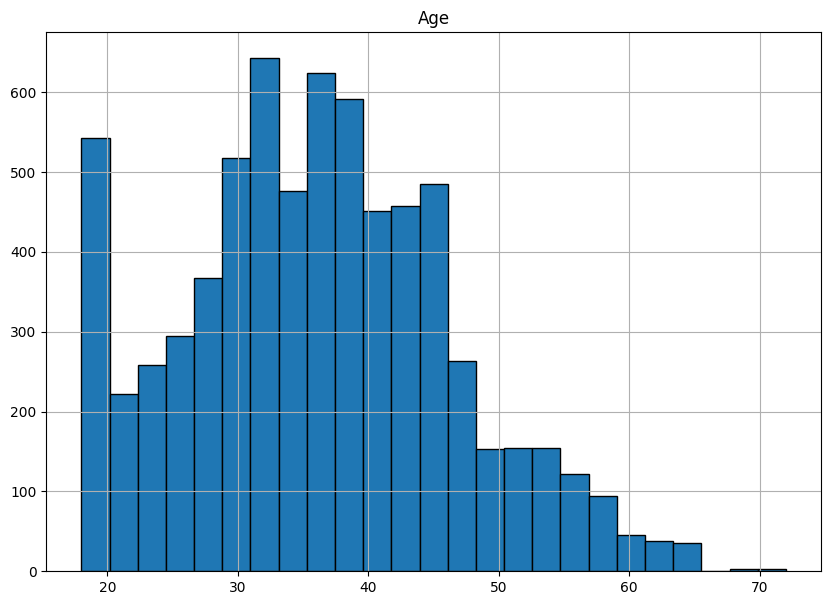

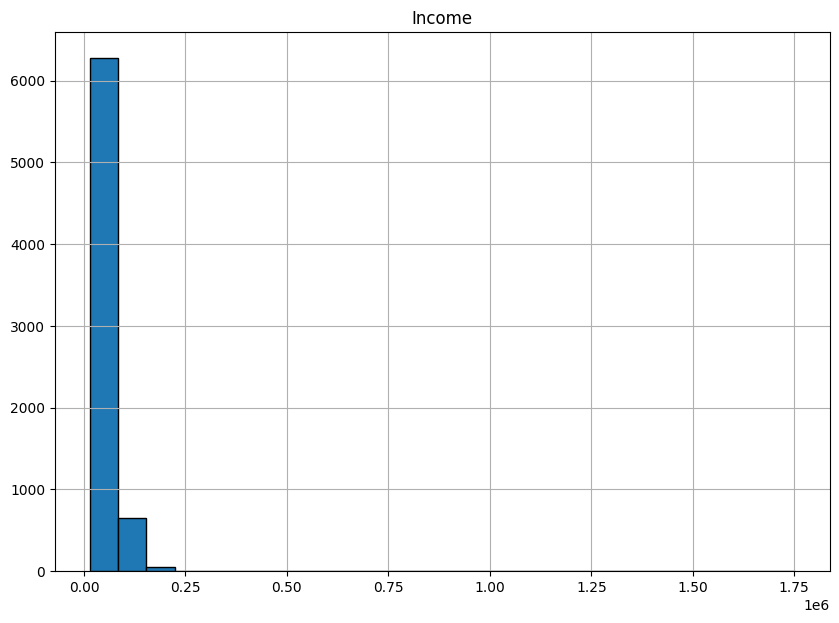

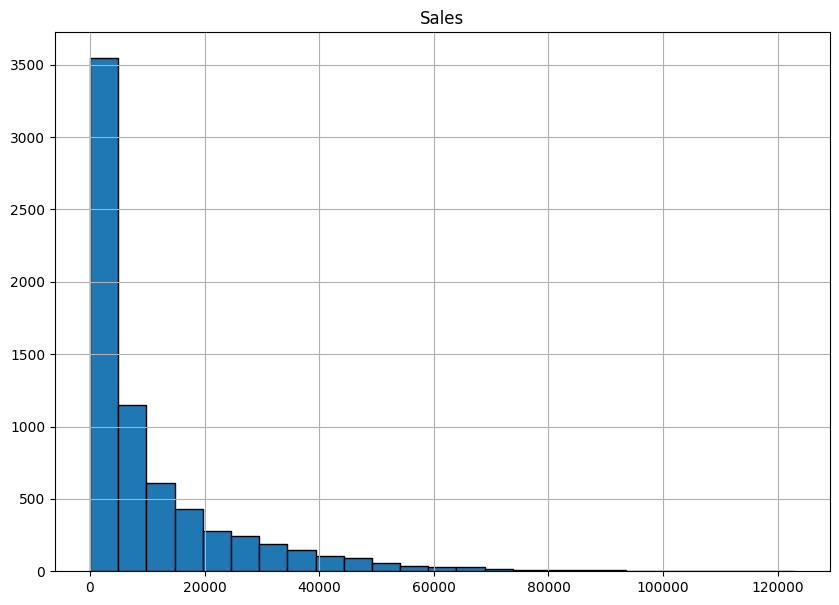

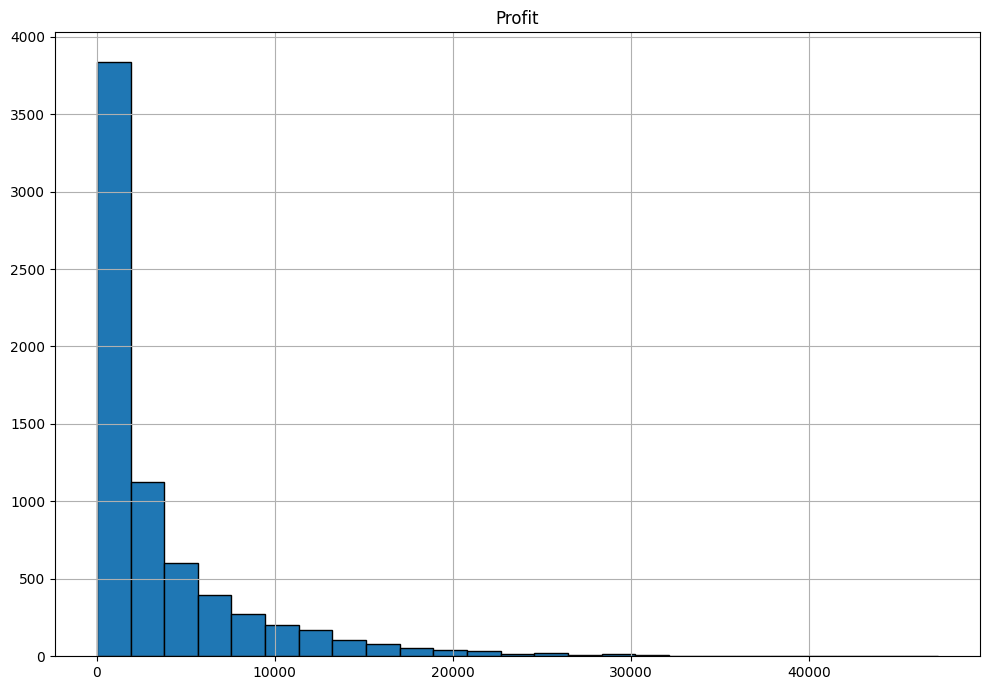

In [72]:
cols = ['Age', 'Income', 'Quantity', 'Unit_Price', 'Discount', 'Sales', 'Cost', 'Profit']

stat = pd.DataFrame({
    'Mean': clean_df[cols].mean(),
    'Median': clean_df[cols].median(),
    'Mode': clean_df[cols].mode().iloc[0],
    'Std_Dev': clean_df[cols].std(),
    'Variance': clean_df[cols].var(),
    'Q1 (25%)': clean_df[cols].quantile(0.25),
    'Q3 (75%)': clean_df[cols].quantile(0.75),
    'IQR': clean_df[cols].quantile(0.75) - clean_df[cols].quantile(0.25),
    'Skewness': clean_df[cols].skew()
})
print(stat.round(2))

# Frequency and proportion (%) for categorical variables
for col in ['Region', 'Product_Category', 'Customer_Segment']:
    freq = clean_df[col].value_counts()
    prop = (clean_df[col].value_counts(normalize=True) * 100).round(2)
    print(f"\n--- {col} ---")
    print(pd.DataFrame({'Frequency': freq, 'Proportion (%)': prop}))

# Univariate histograms for 4 numerical variables
clean_df[['Age']].hist(bins=25, figsize=(10, 7), edgecolor='black')
clean_df[['Income']].hist(bins=25, figsize=(10, 7), edgecolor='black')
clean_df[['Sales']].hist(bins=25, figsize=(10, 7), edgecolor='black')
clean_df[['Profit']].hist(bins=25, figsize=(10, 7), edgecolor='black')
plt.tight_layout()
plt.show()

### 3.5 Outlier Detection (IQR Method)
Applying the IQR rule (`Q1 - 1.5 * IQR` to `Q3 + 1.5 * IQR`) to `Sales`, `Profit`, `Age`, and `Income`:
- **Sales (632 high outliers, up to ₹1,22,951) & Profit (640 high outliers, up to ₹47,234):** Genuine extreme cases caused by high-priced Electronics/Furniture items and multi-unit orders—retained.
- **Age (10 high outliers, ages 65–72):** Genuine senior shoppers after removing impossible ages earlier—retained.
- **Income (278 high outliers, up to ₹17.51 lakh):** Genuine high-income customers on the right tail of the income distribution—retained.

Sales: 632 outliers | Lower = -16604.37, Upper = 32515.17, Max = 122950.97


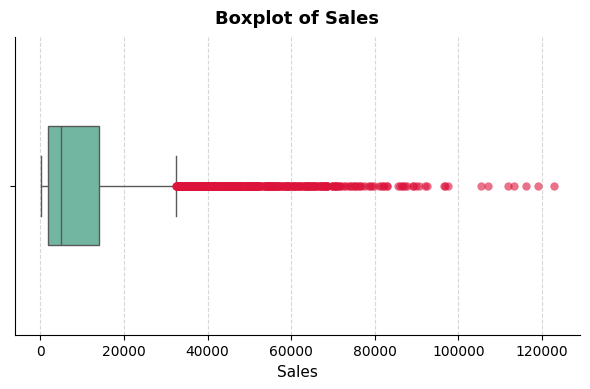

Profit: 640 outliers | Lower = -5364.72, Upper = 10472.09, Max = 47233.61


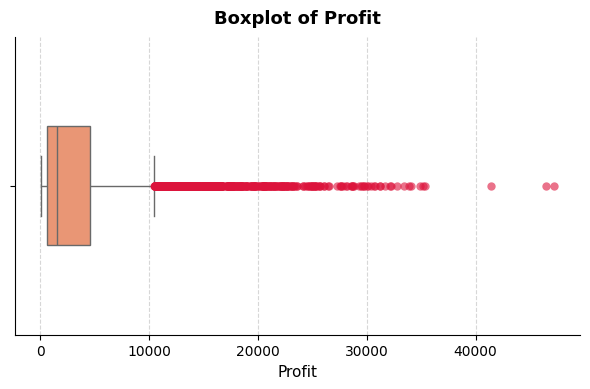

Age: 10 outliers | Lower = 8.00, Upper = 64.00, Max = 72.00


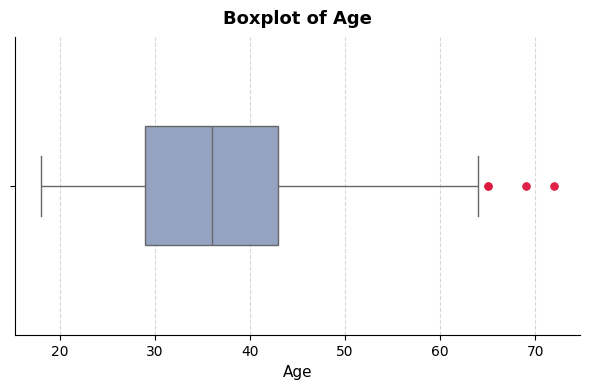

Income: 278 outliers | Lower = -3911.16, Upper = 106006.92, Max = 1750890.41


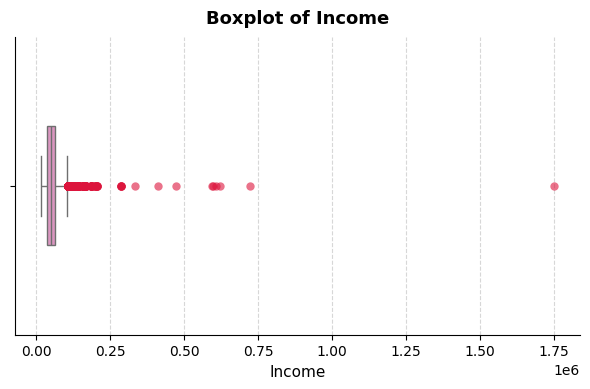

In [73]:
cols = ['Sales', 'Profit', 'Age', 'Income']
palette = sns.color_palette('Set2', len(cols))

for col, color in zip(cols, palette):
  # 1. IQR Outlier Calculation
  q1 = clean_df[col].quantile(0.25)
  q3 = clean_df[col].quantile(0.75)
  iqr = q3 - q1
  lower = q1 - 1.5 * iqr
  upper = q3 + 1.5 * iqr
  outliers = clean_df[(clean_df[col] < lower) | (clean_df[col] > upper)]
  print(
      f'{col}: {len(outliers)} outliers | Lower = {lower:.2f}, Upper ='
      f' {upper:.2f}, Max = {clean_df[col].max():.2f}'
  )


  plt.figure(figsize=(6, 4))
  sns.boxplot(
      x=clean_df[col],  # Horizontal layout works great for individual plots
      color=color,
      width=0.4,
      flierprops=dict(
          marker='o',
          markerfacecolor='crimson',
          markersize=6,
          alpha=0.6,
          markeredgecolor='none',
      ),
  )
  plt.title(f'Boxplot of {col}', fontsize=13, fontweight='bold', pad=10)
  plt.xlabel(col, fontsize=11)
  plt.grid(axis='x', linestyle='--', alpha=0.5)
  sns.despine(top=True, right=True)
  plt.tight_layout()
  plt.show()


### 3.6 Feature Engineering and Grouping
Creating 3 calculated columns (`Profit_Margin`, `Delivery_Days`, and `Order_Year`) and answering 5 business questions using `groupby()`.

In [74]:
clean_df['Profit_Margin'] = (clean_df['Profit'] / clean_df['Sales']) * 100
clean_df['Delivery_Days'] = (clean_df['Delivery_Date'] - clean_df['Order_Date']).dt.days
clean_df['Order_Year'] = clean_df['Order_Date'].dt.year

clean_df[['Profit_Margin', 'Delivery_Days', 'Order_Year']].head()

,Profit_Margin,Delivery_Days,Order_Year
0,33.506128,6.0,2023
1,26.977932,4.0,2023
2,39.029546,8.0,2023
3,36.567360,4.0,2024
4,33.618106,7.0,2024


Answering 5 business questions using `groupby()` and aggregation, then saving the cleaned dataset to CSV.

In [75]:
# Q1: Which region has the highest average order value and profit margin?
print("1. Average Sales, Profit & Margin (%) by Region:")
print(clean_df.groupby('Region')[['Sales', 'Profit', 'Profit_Margin']].mean().round(2))

# Q2: Which product category generates the highest total revenue and profit?
print("\n2. Total Sales & Profit by Product Category:")
print(clean_df.groupby('Product_Category')[['Sales', 'Profit']].sum().round(2))

# Q3: Which customer segment has the highest average order value?
print("\n3. Average Order Value & Profit by Customer Segment:")
print(clean_df.groupby('Customer_Segment')[['Sales', 'Profit']].mean().round(2))

# Q4: How do delivery times and return rates vary across delivery modes?
clean_df['Returned_Flag'] = (clean_df['Returned'] == 'Yes').astype(int)
print("\n4. Avg Delivery Days & Return Rate (%) by Delivery Mode:")
q4 = clean_df.groupby('Delivery_Mode').agg(
    Avg_Delivery_Days=('Delivery_Days', 'mean'),
    Return_Rate_Pct=('Returned_Flag', lambda x: x.mean() * 100)
)
print(q4.round(2))

# Q5: Which payment method is used most and brings the highest average sales?
print("\n5. Order Count & Average Sales by Payment Method:")
print(clean_df.groupby('Payment_Method')['Sales'].agg(['count', 'mean']).round(2))

# Drop temporary helper column before saving final CSV
clean_df = clean_df.drop(columns=['Returned_Flag'])
clean_df.to_csv('cleaned_retail_customer_sales.csv', index=False)
print("\nSaved cleaned_retail_customer_sales.csv successfully! Final shape:", clean_df.shape)

1. Average Sales, Profit & Margin (%) by Region:
           Sales   Profit  Profit_Margin
Region                                  
East    11341.75  3743.72          32.95
North   10777.98  3502.11          32.51
South   10726.92  3508.10          32.50
West    10989.43  3600.07          32.54

2. Total Sales & Profit by Product Category:
                        Sales       Profit
Product_Category                          
Clothing           7781680.39   2521027.84
Electronics       37639557.39  12352219.50
Furniture         26057893.88   8547604.77
Grocery            2685875.10    874840.19
Office Supplies    2566182.51    832190.36

3. Average Order Value & Profit by Customer Segment:
                     Sales   Profit
Customer_Segment                   
Consumer          10864.30  3568.64
Corporate         11140.59  3625.95
Home Office       10957.07  3593.74

4. Avg Delivery Days & Return Rate (%) by Delivery Mode:
               Avg_Delivery_Days  Return_Rate_Pct
Delivery_Mode   